# 03 — Exploratory Data Analysis

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Understand data distributions, trends, correlations, and treatment/control balance  
**Input:** `data/interim/` (from Notebook 02)  
**Output:** Exploratory figures in `outputs/figures/eda/`, summary statistics

---

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.visualization import set_publication_style, save_figure, COLORS, SECTOR_COLORS

INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

set_publication_style()

%load_ext watermark
%watermark -v -p pandas,numpy,matplotlib,seaborn,plotly

Python implementation: CPython
Python version       : 3.10.11
IPython version      : 8.39.0

pandas    : 2.3.3
numpy     : 2.0.2
matplotlib: 3.10.9
seaborn   : 0.13.2
plotly    : 5.24.1



In [2]:
# Load cleaned data
df = pd.read_csv(INTERIM_DIR / "covariates_merged.csv")
df_policies = pd.read_csv(INTERIM_DIR / "policies_cleaned.csv")

print(f"Panel: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Countries: {df['iso3'].nunique()}, Years: {df['year'].min()}-{df['year'].max()}")
print(f"\nPolicies: {len(df_policies)} entries, {df_policies['iso3'].nunique()} countries")

Panel: 7,630 rows × 37 columns
Countries: 218, Years: 1990-2024

Policies: 13167 entries, 197 countries


---
## 3.1 — Global Emission Trends

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\global_co2_trend.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\global_co2_trend.pdf


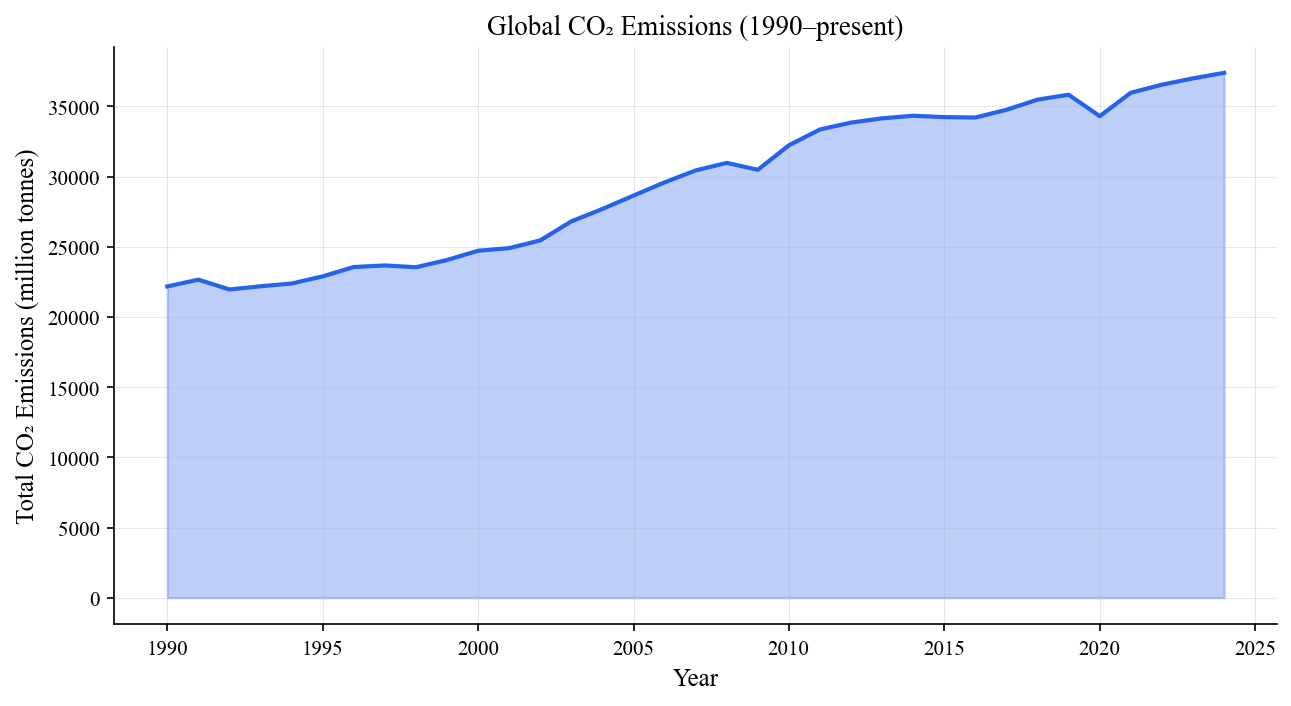

In [3]:
# Global CO₂ emissions over time
global_co2 = df.groupby("year")["co2"].sum().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(global_co2["year"], global_co2["co2"], alpha=0.3, color=COLORS["primary"])
ax.plot(global_co2["year"], global_co2["co2"], color=COLORS["primary"], linewidth=2)
ax.set_xlabel("Year")
ax.set_ylabel("Total CO₂ Emissions (million tonnes)")
ax.set_title("Global CO₂ Emissions (1990–present)")
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
save_figure(fig, "global_co2_trend", subdir="eda")
plt.show()

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\top10_emitters_trajectory.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\top10_emitters_trajectory.pdf


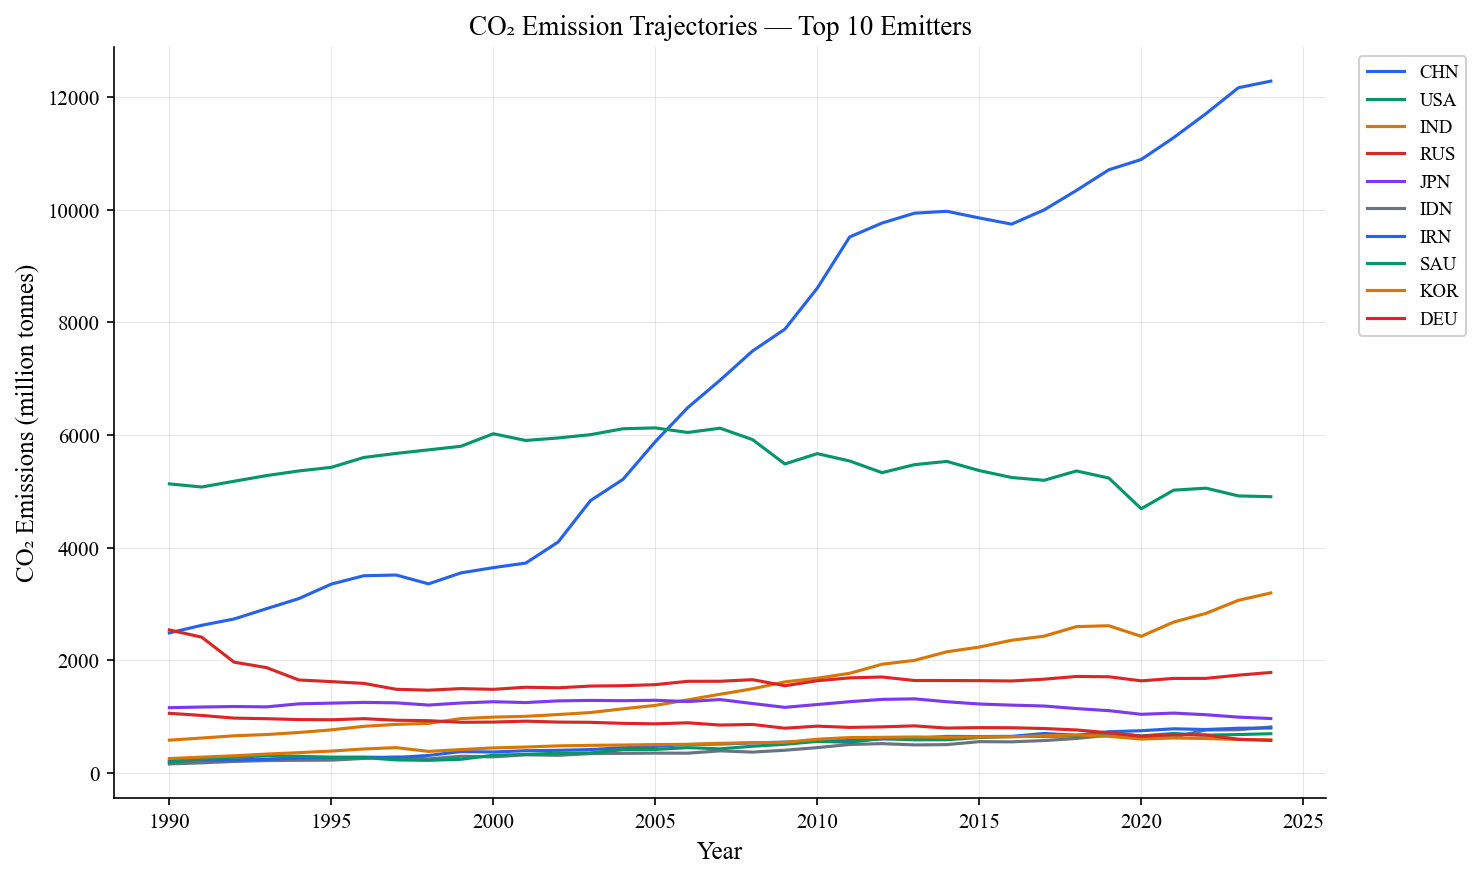

In [4]:
# Top 10 emitters — trajectories
latest_year = df["year"].max()
top10 = df[df["year"] == latest_year].nlargest(10, "co2")["iso3"].tolist()

fig, ax = plt.subplots(figsize=(10, 6))
for iso in top10:
    country_data = df[df["iso3"] == iso]
    ax.plot(country_data["year"], country_data["co2"], linewidth=1.5, label=iso)

ax.set_xlabel("Year")
ax.set_ylabel("CO₂ Emissions (million tonnes)")
ax.set_title("CO₂ Emission Trajectories — Top 10 Emitters")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
save_figure(fig, "top10_emitters_trajectory", subdir="eda")
plt.show()

---
## 3.2 — Policy Adoption Timeline

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\policy_adoption_timeline.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\policy_adoption_timeline.pdf


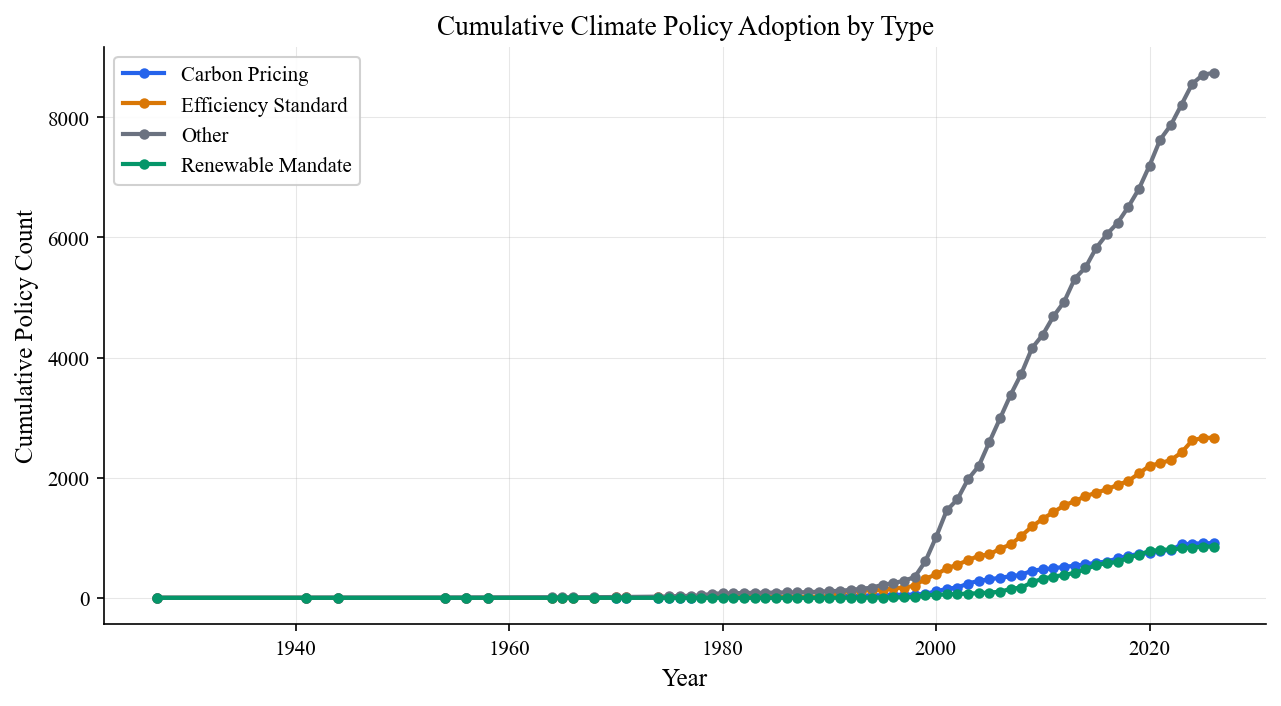

In [5]:
# Cumulative policy adoption by type
policy_counts = (
    df_policies
    .groupby(["year_adopted", "policy_category"])
    .size()
    .reset_index(name="count")
    .sort_values("year_adopted")
)

policy_cumulative = (
    policy_counts
    .pivot_table(index="year_adopted", columns="policy_category", values="count", fill_value=0)
    .cumsum()
)

fig, ax = plt.subplots(figsize=(10, 5))
category_colors = {
    "Carbon Pricing": COLORS["primary"],
    "Renewable Mandate": COLORS["success"],
    "Efficiency Standard": COLORS["warning"],
}

for col in policy_cumulative.columns:
    color = category_colors.get(col, COLORS["neutral"])
    ax.plot(policy_cumulative.index, policy_cumulative[col],
            linewidth=2, marker="o", markersize=4, label=col, color=color)

ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Policy Count")
ax.set_title("Cumulative Climate Policy Adoption by Type")
ax.legend()
save_figure(fig, "policy_adoption_timeline", subdir="eda")
plt.show()

In [6]:
# Policy adoption map — which countries have carbon pricing
carbon_pricing_countries = df_policies[
    df_policies["policy_category"] == "Carbon Pricing"
]["iso3"].unique()

all_countries = df["iso3"].unique()
map_data = pd.DataFrame({
    "iso3": all_countries,
    "has_carbon_pricing": [1 if c in carbon_pricing_countries else 0 for c in all_countries]
})

fig_map = px.choropleth(
    map_data,
    locations="iso3",
    color="has_carbon_pricing",
    color_continuous_scale=["#f0f0f0", COLORS["primary"]],
    title="Countries with Carbon Pricing Mechanisms",
    labels={"has_carbon_pricing": "Carbon Pricing"},
)
fig_map.update_layout(width=900, height=450, margin=dict(t=50, b=0, l=0, r=0))
fig_map.show()

---
## 3.3 — Correlation Analysis

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\correlation_matrix.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\correlation_matrix.pdf


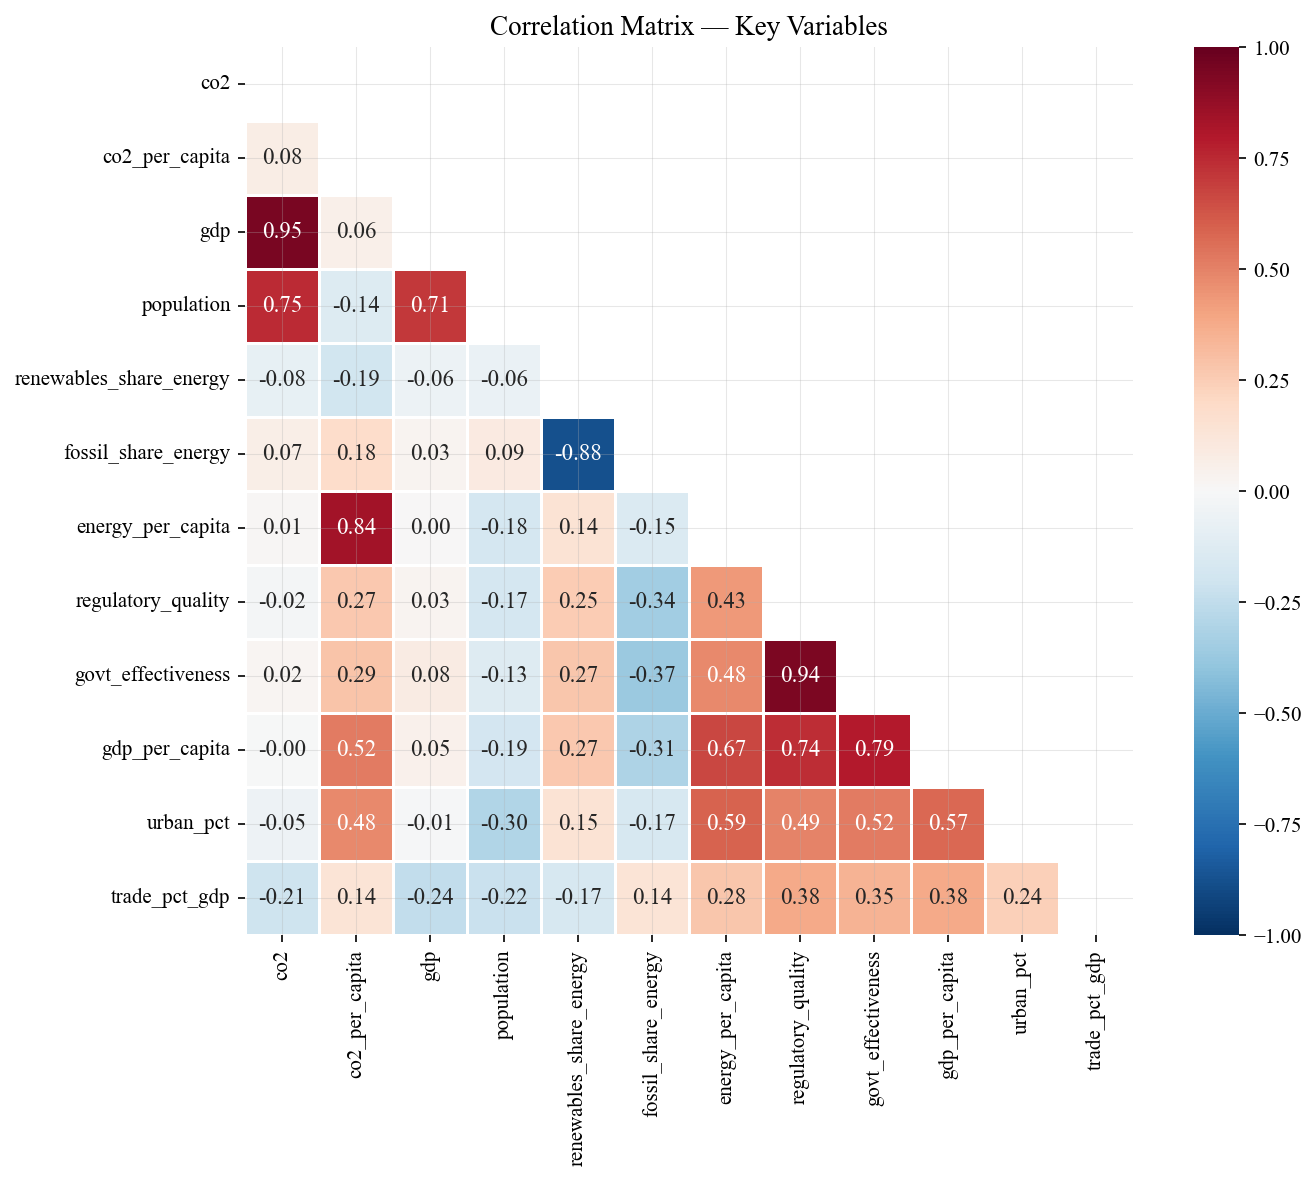

In [7]:
# Correlation matrix of key variables
corr_vars = ["co2", "co2_per_capita", "gdp", "population"]

# Add available energy/governance columns
for col in ["renewables_share_energy", "fossil_share_energy", "energy_per_capita",
            "regulatory_quality", "govt_effectiveness", "gdp_per_capita",
            "urban_pct", "trade_pct_gdp"]:
    if col in df.columns:
        corr_vars.append(col)

corr_data = df[corr_vars].dropna()
corr_matrix = corr_data.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=ax, vmin=-1, vmax=1,
            square=True, linewidths=0.5)
ax.set_title("Correlation Matrix — Key Variables")
plt.tight_layout()
save_figure(fig, "correlation_matrix", subdir="eda")
plt.show()

---
## 3.4 — Treatment vs Control Balance

In [8]:
# Create treatment indicator: does this country have carbon pricing by this year?
first_adoption = (
    df_policies[df_policies["policy_category"] == "Carbon Pricing"]
    .groupby("iso3")["year_adopted"]
    .min()
    .reset_index()
    .rename(columns={"year_adopted": "cp_first_year"})
)

df_balance = df.merge(first_adoption, on="iso3", how="left")
df_balance["treated"] = (df_balance["year"] >= df_balance["cp_first_year"]).fillna(False).astype(int)

# Balance diagnostics
balance_vars = ["co2_per_capita", "gdp_per_capita", "population"]
balance_vars = [v for v in balance_vars if v in df_balance.columns]

print("Treatment/Control Balance (latest year):")
print(f"{'─' * 50}")
latest = df_balance[df_balance["year"] == df_balance["year"].max()]
for var in balance_vars:
    treated_mean = latest[latest["treated"] == 1][var].mean()
    control_mean = latest[latest["treated"] == 0][var].mean()
    print(f"{var:25s} | Treated: {treated_mean:12,.1f} | Control: {control_mean:12,.1f}")

print(f"\nTreated countries: {latest[latest['treated']==1]['iso3'].nunique()}")
print(f"Control countries: {latest[latest['treated']==0]['iso3'].nunique()}")

Treatment/Control Balance (latest year):
──────────────────────────────────────────────────
co2_per_capita            | Treated:          5.5 | Control:          4.1
gdp_per_capita            | Treated:     23,790.8 | Control:     13,227.6
population                | Treated: 82,733,967.8 | Control: 10,210,275.8

Treated countries: 82
Control countries: 136


C:\Users\Admin\AppData\Local\Temp\ipykernel_15896\3765640343.py:19: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\treatment_control_balance.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\treatment_control_balance.pdf


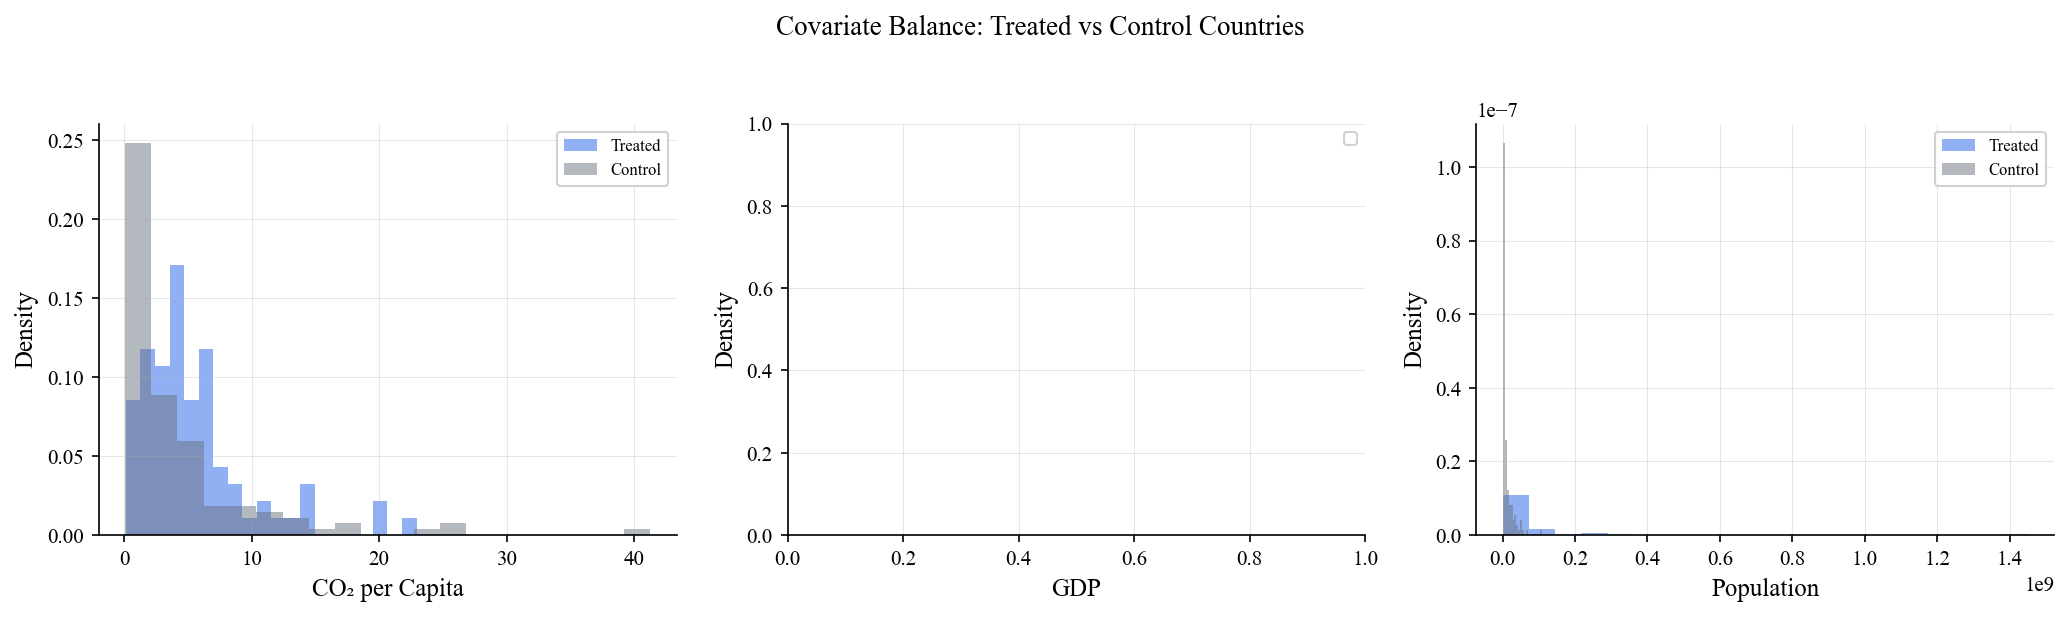

In [9]:
# Distribution comparison: treated vs control
if "co2_per_capita" in df_balance.columns:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    compare_vars = [("co2_per_capita", "CO₂ per Capita"),
                    ("gdp", "GDP"),
                    ("population", "Population")]
    compare_vars = [(v, l) for v, l in compare_vars if v in df_balance.columns]

    for idx, (var, label) in enumerate(compare_vars[:3]):
        ax = axes[idx]
        for treated, group_label, color in [(1, "Treated", COLORS["primary"]),
                                             (0, "Control", COLORS["neutral"])]:
            data = latest[latest["treated"] == treated][var].dropna()
            if len(data) > 0:
                ax.hist(data, bins=20, alpha=0.5, label=group_label, color=color, density=True)
        ax.set_xlabel(label)
        ax.set_ylabel("Density")
        ax.legend(fontsize=8)

    fig.suptitle("Covariate Balance: Treated vs Control Countries", fontsize=13, y=1.02)
    plt.tight_layout()
    save_figure(fig, "treatment_control_balance", subdir="eda")
    plt.show()

---
## 3.5 — Missing Data Patterns

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\missing_data_pattern.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\eda\missing_data_pattern.pdf


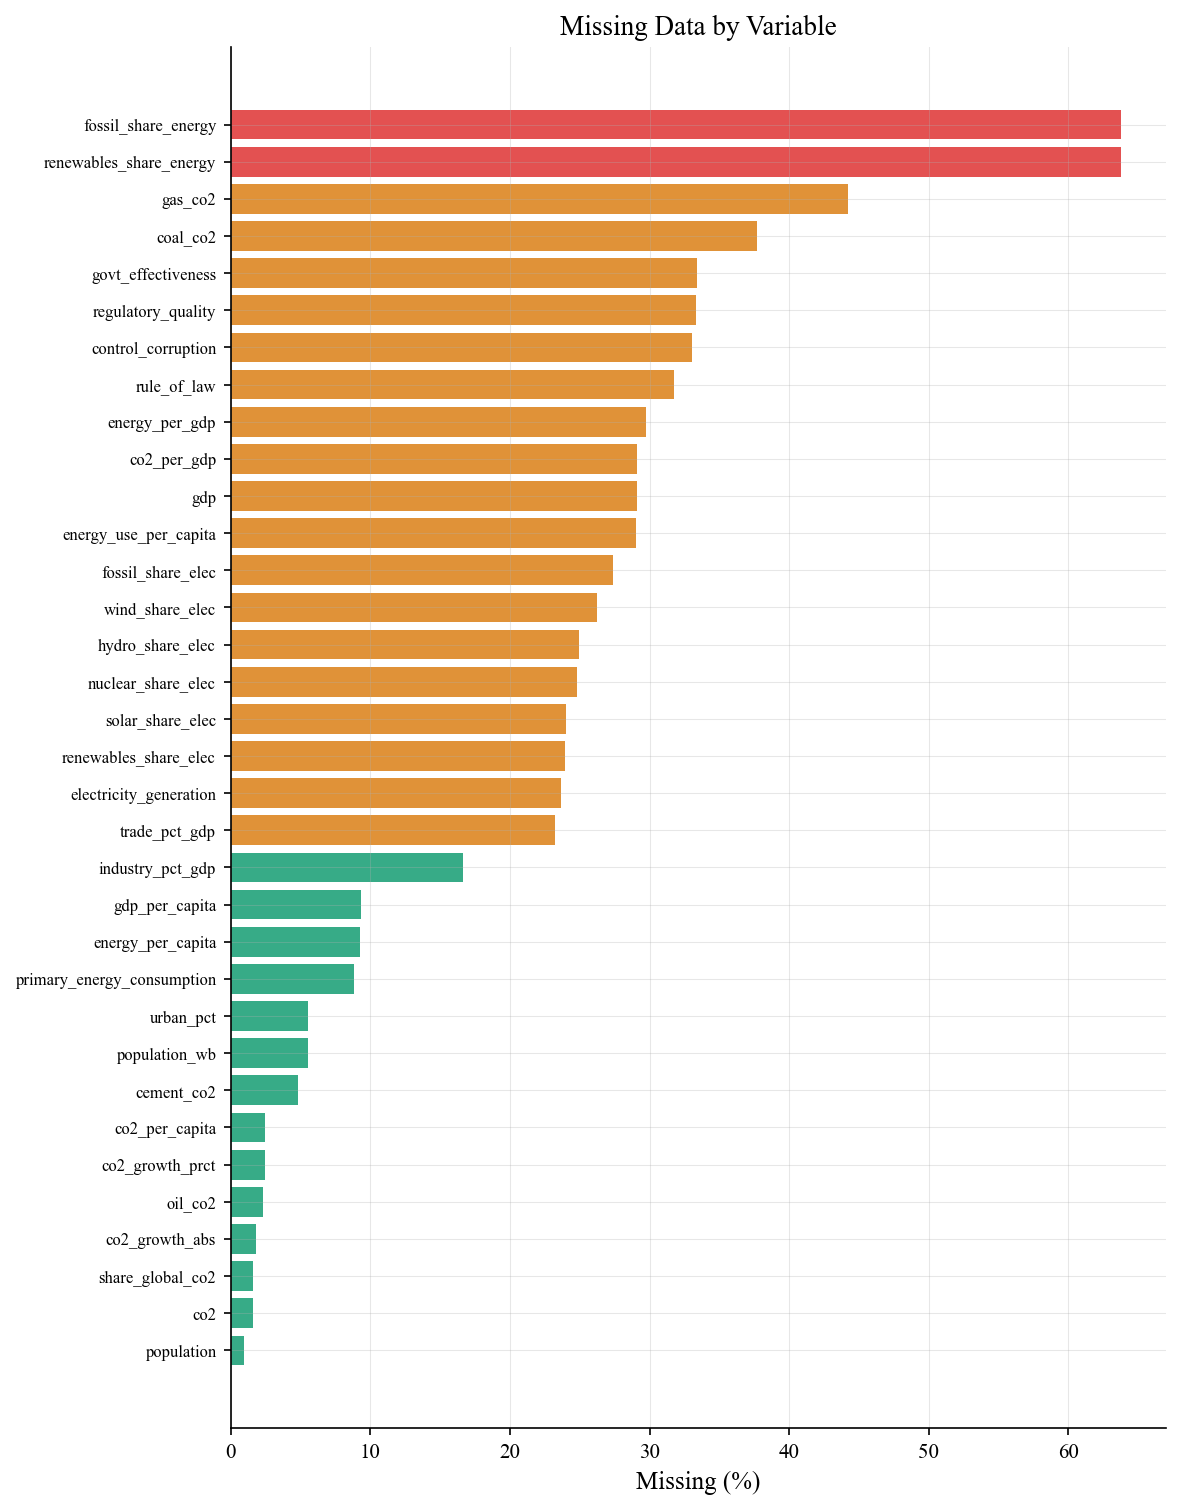

In [10]:
# Missing data heatmap
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

if len(missing_pct) > 0:
    fig, ax = plt.subplots(figsize=(8, max(4, len(missing_pct) * 0.3)))
    colors = [COLORS["danger"] if v > 50 else COLORS["warning"] if v > 20 else COLORS["success"]
              for v in missing_pct.values]
    ax.barh(range(len(missing_pct)), missing_pct.values, color=colors, alpha=0.8)
    ax.set_yticks(range(len(missing_pct)))
    ax.set_yticklabels(missing_pct.index, fontsize=8)
    ax.set_xlabel("Missing (%)")
    ax.set_title("Missing Data by Variable")
    ax.invert_yaxis()
    plt.tight_layout()
    save_figure(fig, "missing_data_pattern", subdir="eda")
    plt.show()
else:
    print(" No missing data!")

---
## 3.6 — Summary Statistics

In [ ]:
# Summary statistics table
summary_vars = ["co2", "co2_per_capita", "gdp", "population"]
summary_vars = [v for v in summary_vars if v in df.columns]

for extra in ["renewables_share_energy", "fossil_share_energy", "gdp_per_capita",
              "urban_pct", "regulatory_quality"]:
    if extra in df.columns:
        summary_vars.append(extra)

summary = df[summary_vars].describe().T
summary["missing_%"] = (df[summary_vars].isnull().mean() * 100).round(1)
summary = summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "missing_%"]]

print("\n Summary Statistics (Panel Data)")
print("=" * 80)
display(summary.round(2))

# Save
summary.to_csv(PROJECT_ROOT / "outputs" / "tables" / "summary_statistics.csv")
print("\n Summary statistics saved to outputs/tables/")
print("  Proceed to Notebook 04: Feature Engineering")


 Summary Statistics (Panel Data)


,count,mean,std,min,25%,50%,75%,max,missing_%
co2,7508.0,1.375400e+02,6.752900e+02,0.000000e+00,8.500000e-01,7.170000e+00,5.394000e+01,1.228904e+04,1.6
co2_per_capita,7442.0,5.020000e+00,7.790000e+00,0.000000e+00,7.100000e-01,2.740000e+00,6.830000e+00,3.647900e+02,2.5
gdp,5410.0,4.894066e+11,1.704830e+12,2.571720e+08,1.885143e+10,6.108450e+10,2.913226e+11,2.696602e+13,29.1
population,7560.0,3.130214e+07,1.253051e+08,5.010000e+02,6.340445e+05,5.512436e+06,2.003905e+07,1.450936e+09,0.9
renewables_share_energy,2765.0,1.139000e+01,1.440000e+01,0.000000e+00,1.480000e+00,5.890000e+00,1.667000e+01,8.613000e+01,63.8
fossil_share_energy,2765.0,8.445000e+01,1.644000e+01,1.387000e+01,7.754000e+01,8.839000e+01,9.721000e+01,1.000000e+02,63.8
gdp_per_capita,6919.0,1.374841e+04,2.124310e+04,1.667100e+02,1.528650e+03,4.648230e+03,1.761027e+04,2.471702e+05,9.3
urban_pct,7210.0,5.675000e+01,2.383000e+01,5.270000e+00,3.653000e+01,5.767000e+01,7.550000e+01,1.000000e+02,5.5
regulatory_quality,5086.0,-5.000000e-02,1.000000e+00,-2.950000e+00,-7.600000e-01,-1.700000e-01,7.000000e-01,2.260000e+00,33.3



 Summary statistics saved to outputs/tables/
  Proceed to Notebook 04: Feature Engineering


: 